# DiscoCH: Near-real time operation on FORCE corrected Sentinel-2 VIs

In [1]:
# User defined parameters
network_directory = r"\\speedy16-36\Data_23\FORCE\FORCE_Kingslide\level3_tss"  # Location of FORCE VI data on network
force_directory = r'B:\bloomc\DiscoCH_2026_08_03\FORCE\level3_tss'  # Local location to save the FORCE VI data
output_dir = "../output"  # Where to save output data
force_tiles_to_process = r"..\data\CH_FORCE_Grids.csv"  # Tiles to process (Tile_ID column) -- local copy in the project's data folder
disco_model = r"..\data\empirical_discoloration_model_pipeline_2025_6_2.pkl"  # Pre-trained Discoloration Model -- local copy in the project's data folder
mask_path = r"..\data\DiscoCH_2026_Mask.tif"
year = 2025

In [2]:
# Libraries
import os
from datetime import date
import matplotlib.pyplot as plt

from src.disco_ch_operational.transfer import transfer
from src.disco_ch_operational.interpolate import interpolate_tiles
from src.disco_ch_operational.apply_model import apply_discoch_tiles
from src.disco_ch_operational.mask import mask_and_scale_dir
from src.disco_ch_operational.validate import validate_threshold, validate_thresholds
from src.disco_ch_operational.disco_statistics import summarize_discoloration
from src.disco_ch_operational.compare import plot_year_comparison
from src.disco_ch_operational.hexmap import plot_hex_maps

# Reset to the standard light theme for plots
plt.style.use('default')

# Explicitly force figures to white:
plt.rcParams['figure.facecolor'] = 'white'
plt.rcParams['axes.facecolor'] = 'white'

## Transfer data

In [3]:
# Transfer VI data from the network to a local drive
transfer(network_directory, str(year), force_directory, dry_run=True)

Scanning source: \\speedy16-36\Data_23\FORCE\FORCE_Kingslide\level3_tss
Matching filenames containing: '2025'
Destination: B:\bloomc\DiscoCH_2026_08_03\FORCE\level3_tss
Dry run: True
------------------------------------------------------------
Matched files:        350
Already up to date:   350
Need copying:         0  (0.0B)
------------------------------------------------------------
Nothing to copy. Done.


## Interpolate

In [4]:
# The date up to which the code should be run: output dates are produced up to
# 5 days before this, each using data up to 5 days after it. date.today() in an
# operational setting when the code is run daily; never a date in the future.
date_to_run_to = date(year, 10, 5)

# Create output directory
force_output = os.path.join(output_dir, 'DiscoCH_rbf_10_20_30')
rbf_output = os.path.join(force_output, 'level4_rbf', str(year))
os.makedirs(rbf_output, exist_ok=True)

# Canonical VI name -> token used in the 2026 FORCE file names
vi_keys = {
    "NDVI": "NDVI",
    "EVI": "EVI",
    "NDMI": "NDMI",
    "CIRE": "CIre",
    "CCI": "CCI",
}

results = interpolate_tiles(
    tss_dir=force_directory,
    out_dir=rbf_output,
    vi_keys=vi_keys,
    date_range=(date(year, 1, 1), date(year, 12, 31)),
    as_of=date_to_run_to,      # None = full season, no lag (e.g. training years)
    lag_days=5,
    int_day=5,
    rbf_sigma=(10, 20, 30), rbf_cutoff=0.95,
    despike=False,
    tiles_csv=force_tiles_to_process,  # only these Tile_IDs are processed
    skip_existing=True,        # keep dates already written, only add new ones
    chunk_size=512,
    max_workers=10,
)

for tile_id, by_vi in results.items():
    for vi, (tss_path, out_path, status) in by_vi.items():
        if status.startswith("failed"):
            print(f"{tile_id}/{vi}: {status}")

  tiles_csv (CH_FORCE_Grids.csv, include): 69 of 70 tile(s) selected
Found 69 tile(s) under B:\bloomc\DiscoCH_2026_08_03\FORCE\level3_tss
  [1/345, 2:25, ~13:54:12 left] X0051_Y0066/NDVI: written (55 date(s))
  [2/345, 2:25, ~6:56:52 left] X0051_Y0066/EVI: written (55 date(s))
  [3/345, 2:26, ~4:37:48 left] X0051_Y0066/NDMI: written (55 date(s))
  [4/345, 2:26, ~3:27:49 left] X0051_Y0066/CIRE: written (55 date(s))
  [5/345, 2:26, ~2:46:02 left] X0051_Y0066/CCI: written (55 date(s))
  [6/345, 2:27, ~2:18:30 left] X0052_Y0064/CIRE: written (55 date(s))
  [7/345, 2:27, ~1:58:22 left] X0052_Y0064/NDVI: written (55 date(s))
  [8/345, 2:27, ~1:43:22 left] X0052_Y0064/EVI: written (55 date(s))
  [9/345, 2:27, ~1:31:40 left] X0052_Y0064/NDMI: written (55 date(s))
  [10/345, 2:27, ~1:22:23 left] X0052_Y0064/CCI: written (55 date(s))
  [11/345, 4:46, ~2:24:51 left] X0052_Y0066/CIRE: written (55 date(s))
  [12/345, 4:46, ~2:12:30 left] X0052_Y0066/NDVI: written (55 date(s))
  [13/345, 4:46, ~2:02

## Apply Discoloration Model

In [ ]:
rbf_output = rbf_output if "rbf_output" in dir() else os.path.join(force_output, f'level4_rbf/{str(year)}')
force_output = force_output if "force_output" in dir() else os.path.join(output_dir, 'DiscoCH_rbf_10_20_30')
discoCH_output = os.path.join(force_output, str(year))

# Forest mask (any extent/CRS -- each tile is matched to it automatically); None = all pixels
forest_mask = None

summary = apply_discoch_tiles(
    rbf_dir=rbf_output,
    out_dir=discoCH_output,          # tiles, mosaic/, minmax/, vi_norm/, minmax_by_date/, logs/
    year=year,
    model_path=disco_model,
    vi_keys=vi_keys,                 # same 2026 naming as the interpolation
    tiles_csv=force_tiles_to_process,
    forest_mask_path=forest_mask,
    start_date=f'{year}-01-01',      # min/max uses the season from here on
    model_months=(6, 7, 8, 9),       # model only runs in these months (min/max updates every date)
    export_normalized_vi=True,       # per-date normalized VIs -> vi_norm/
    export_minmax=True,              # per-date min/max snapshots -> minmax_by_date/
    export_start_date=f'{year}-06-01',
    export_end_date=f'{year}-09-30',
    mosaic=True,
    plot_mosaic=False,               # plot each newly mosaicked date
    max_workers=10,
)

## Masking

In [ ]:
# Mask the discoloration results and scale
force_output = force_output if "force_output" in dir() else os.path.join(output_dir, 'DiscoCH_rbf_10_20_30')
discoCH_output = discoCH_output if "discoCH_output" in dir() else os.path.join(force_output, str(year))
masked_output = os.path.join(discoCH_output, 'masked')

status = mask_and_scale_dir(input_dir=os.path.join(discoCH_output, 'mosaic'),
                            mask_path=mask_path,  # None = only reproject to EPSG:2056 and scale
                            output_dir=masked_output,
                            pattern='Disco_Proba_*.tif',
                            threads=4,
                            )

## Validation

Validation polygons cover 172524 pixels of Disco_Proba_2026-08-14.tif; 137858 are valid and scored (34666 nodata dropped).

Threshold sweep (>=) for Disco_Proba_2026-08-14.tif against Mapping_2026.gpkg [Sentinel_2_13_08_2026]:
           n_pixels  n_positive  n_negative     tn     fp     fn     tp  accuracy  balanced_accuracy  precision  recall  specificity      f1  cohen_kappa     iou
threshold                                                                                                                                                        
0            137858       63853       74005      0  74005      0  63853    0.4632             0.5000     0.4632  1.0000       0.0000  0.6331       0.0000  0.4632
500          137858       63853       74005  65255   8750   3213  60640    0.9132             0.9157     0.8739  0.9497       0.8818  0.9102       0.8265  0.8352
1000         137858       63853       74005  69569   4436   4911  58942    0.9322             0.9316     0.9300  0.9231      

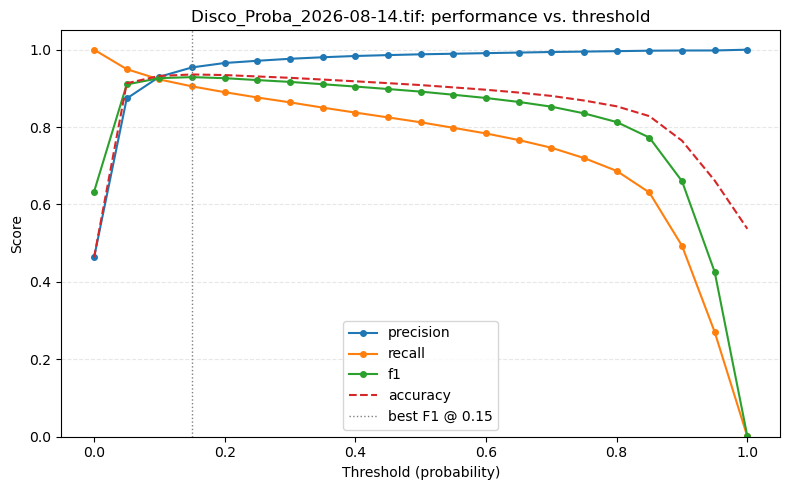

Validation polygons cover 172524 pixels of Disco_Proba_2026-08-14.tif; 137858 are valid and scored (34666 nodata dropped).

Validation of Disco_Proba_2026-08-14.tif against Mapping_2026.gpkg [Sentinel_2_13_08_2026] (threshold >= 1500)
  confusion matrix (rows true 0/1, cols predicted 0/1):
[[71232  2773]
 [ 6053 57800]]
            n_pixels: 137858
          n_positive: 63853
          n_negative: 74005
            accuracy: 0.9360
   balanced_accuracy: 0.9339
           precision: 0.9542
              recall: 0.9052
         specificity: 0.9625
                  f1: 0.9291
         cohen_kappa: 0.8708
                 iou: 0.8675
Saved confusion matrix plot to ../output\DiscoCH_rbf_10_20_30\2026\validation\confusion_matrix_Disco_Proba_2026-08-14_t1500.png


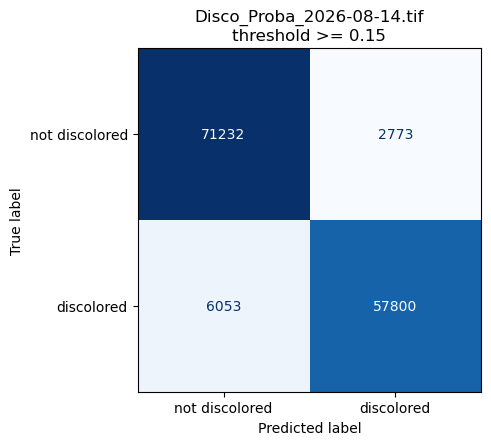

In [3]:
# Calculate Validation statistics
force_output = force_output if "force_output" in dir() else os.path.join(output_dir, 'DiscoCH_rbf_10_20_30')
discoCH_output = discoCH_output if "discoCH_output" in dir() else os.path.join(force_output, str(year))
masked_output = masked_output if "masked_output" in dir() else os.path.join(discoCH_output, 'masked')
validation_output = os.path.join(discoCH_output, 'validation')

validation_gpkg = r"..\..\Validation\Mapping_2026.gpkg"  # Ground-truth polygons, Discolored = 1/0
validation_layer = "Sentinel_2_13_08_2026"                  # One layer per survey (also: Planet_2026_07_10)
proba_tif = os.path.join(masked_output, 'Disco_Proba_2026-08-14.tif')  # Mosaic closest to the survey date

# Sweep thresholds 0, 500, ..., 10000 (stored scale, 4000 = 40 %) to find the best F1
sweep = validate_thresholds(proba_tif, validation_gpkg, layer=validation_layer,
                            output_dir=validation_output)

# Score the best-F1 threshold in detail
validation_metrics = validate_threshold(proba_tif, validation_gpkg, sweep["f1"].idxmax(),
                                        layer=validation_layer, output_dir=validation_output)


## Spatiotemporal Statistics

In [3]:
# Calculate national and district level statistics
force_output = force_output if "force_output" in dir() else os.path.join(output_dir, 'DiscoCH_rbf_10_20_30')
discoCH_output = discoCH_output if "discoCH_output" in dir() else os.path.join(force_output, str(year))
masked_output = masked_output if "masked_output" in dir() else os.path.join(discoCH_output, 'masked')
stats_output = os.path.join(discoCH_output, 'statistics')

districts = r"B:\bloomc\JAG_Manuscript_2026_03_10\JAG_DiscoCH\data\districts\fgeolib_geolib_g1b20_LV95.shp"
threshold = 4000  # Stored value (0-10000) at/above which a pixel is discolored: 4000 = 40 % probability

# Per date: discolored proportion and hectares for all of Switzerland ("All") and each district
stats = summarize_discoloration(masked_output, threshold, zones=districts, zone_field="bzname",
                                year=year, output_dir=stats_output, max_workers=8)


Counting 24 mosaics in ../output\DiscoCH_rbf_10_20_30\2026\masked (34842 x 22066 px, 143 zones), threshold >= 4000 ...
Done in 0:42
             valid_ha  discolored_ha  proportion
date                                            
2026-06-05  251092.03          36.23      0.0001
2026-06-10  251092.59          34.56      0.0001
2026-06-15  251097.39          72.45      0.0003
2026-06-20  251098.23         465.27      0.0019
2026-06-25  251098.29         881.98      0.0035
2026-06-30  251098.35        1329.58      0.0053
2026-07-05  251098.39        1719.95      0.0068
2026-07-10  251098.39        2894.70      0.0115
2026-07-15  251098.40        3577.58      0.0142
2026-07-20  251098.40        6124.43      0.0244
2026-07-25  251098.21        7584.48      0.0302
2026-07-30  251098.24        9917.20      0.0395
2026-08-04  251098.27       12347.41      0.0492
2026-08-09  251098.27       29048.83      0.1157
2026-08-14  251098.21       37148.92      0.1479
2026-08-19  251098.19       45282.2

  Proba_mosaic_2018-05-26.tif covers 36000 x 24000 of the 39000 x 24000 px; pixels outside it count as nodata
  Proba_mosaic_2018-05-31.tif covers 36000 x 24000 of the 39000 x 24000 px; pixels outside it count as nodata
Counting 27 mosaics in B:\bloomc\JAG_Manuscript_2026_03_10\JAG_DiscoCH\output\disco_predictions\2026_03_21\mosaics (39000 x 24000 px), threshold >= 4000 ...
Done in 0:31
Saved ../output\DiscoCH_rbf_10_20_30\2026\statistics\discoloration_comparison_2018_vs_2026.png and discoloration_comparison_2018_vs_2026.csv


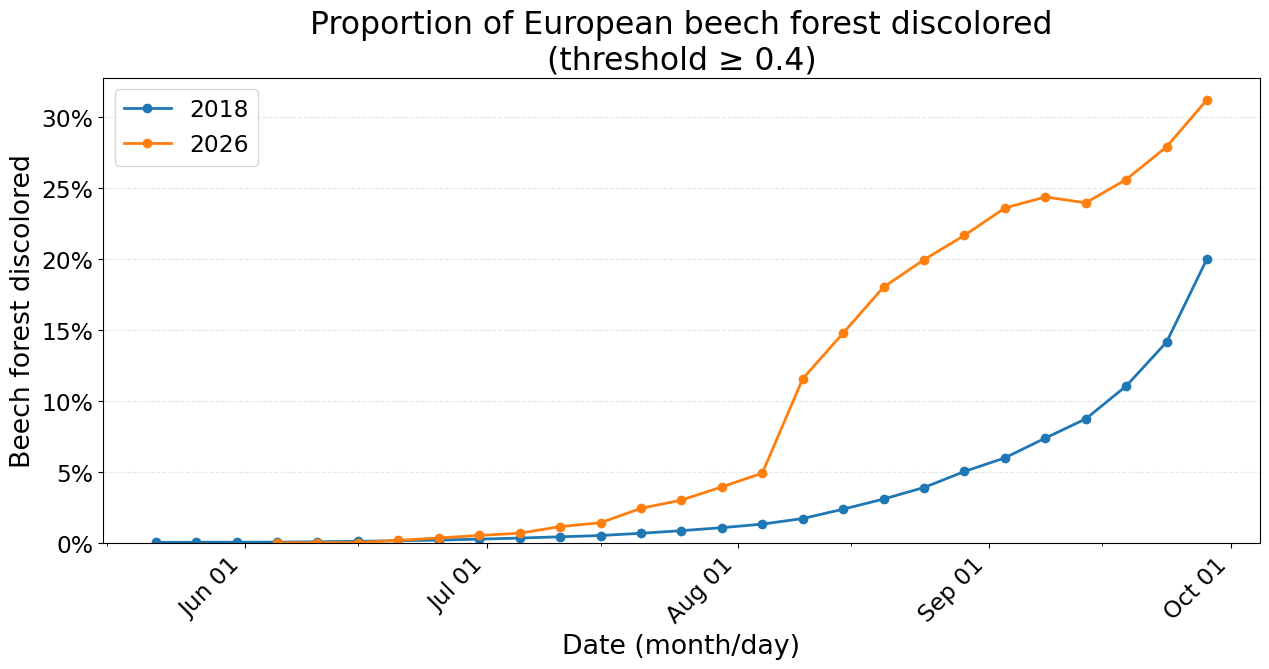

In [4]:
# Compare the season with 2018 (Bloom et al. 2026 mosaics), aligned by month/day
mosaics_2018 = r"B:\bloomc\JAG_Manuscript_2026_03_10\JAG_DiscoCH\output\disco_predictions\2026_03_21\mosaics"

comparison = plot_year_comparison(
    {
        "2018": dict(mosaic_dir=mosaics_2018, pattern="Proba_mosaic_*.tif", year=2018),
        str(year): stats,              # already counted above
    },
    threshold=threshold,
    output_dir=stats_output,
    max_workers=8,
)
# Per district: add zones=districts (so 2018 is counted by district too) and e.g.
# regions=["All", "Bezirk Aarau", "Distretto di Lugano"], layout="panels" (or "overlay").


## Hexagon Maps

14,137 hexagons of 3 km2

2018:
  Proba_mosaic_2018-05-26.tif covers 36000 x 24000 of the 39000 x 24000 px; pixels outside it count as nodata
  Proba_mosaic_2018-05-31.tif covers 36000 x 24000 of the 39000 x 24000 px; pixels outside it count as nodata
Counting 27 mosaics in B:\bloomc\JAG_Manuscript_2026_03_10\JAG_DiscoCH\output\disco_predictions\2026_03_21\mosaics (39000 x 24000 px, 14137 zones), threshold >= 4000 ...
Done in 0:45
  8,045 of 14,137 hexagons have data
Saved 8,045 hexagons x 27 dates to ../output\DiscoCH_rbf_10_20_30\2026\statistics\hex_2018_t4000.gpkg

2026:
Counting 24 mosaics in ../output\DiscoCH_rbf_10_20_30\2026\masked (34842 x 22066 px, 14137 zones), threshold >= 4000 ...
Done in 0:36
  8,556 of 14,137 hexagons have data
Saved 8,556 hexagons x 24 dates to ../output\DiscoCH_rbf_10_20_30\2026\statistics\hex_2026_t4000.gpkg
Saved ../output\DiscoCH_rbf_10_20_30\2026\statistics\hex_discoloration_2018_vs_2026_t4000.png
Wrote run parameters to ../output\DiscoCH_rbf_10_20_

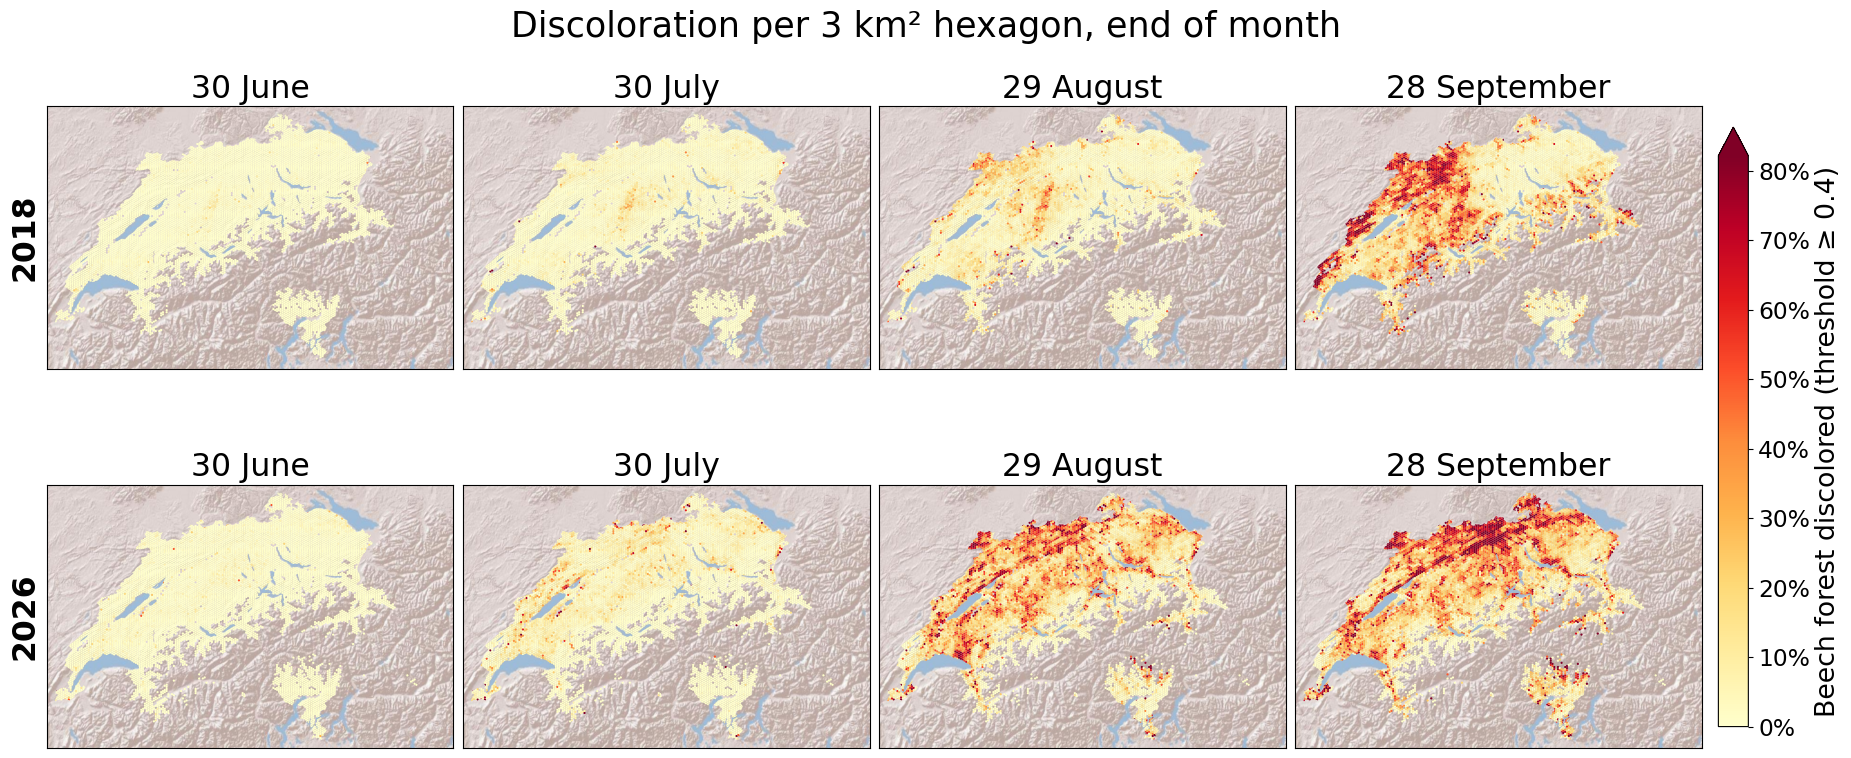

Done in 1:42


In [3]:
# End-of-month hexagon maps, 2018 vs this year (also saves hex_<year>_t<threshold>.gpkg with one field per date)
force_output = force_output if "force_output" in dir() else os.path.join(output_dir, 'DiscoCH_rbf_10_20_30')
discoCH_output = discoCH_output if "discoCH_output" in dir() else os.path.join(force_output, str(year))
masked_output = masked_output if "masked_output" in dir() else os.path.join(discoCH_output, 'masked')
stats_output = stats_output if "stats_output" in dir() else os.path.join(discoCH_output, 'statistics')
districts = districts if "districts" in dir() else r"B:\bloomc\JAG_Manuscript_2026_03_10\JAG_DiscoCH\data\districts\fgeolib_geolib_g1b20_LV95.shp"
mosaics_2018 = mosaics_2018 if "mosaics_2018" in dir() else r"B:\bloomc\JAG_Manuscript_2026_03_10\JAG_DiscoCH\output\disco_predictions\2026_03_21\mosaics"
threshold = threshold if "threshold" in dir() else 4000

hexes = plot_hex_maps(
    {
        "2018": dict(mosaic_dir=mosaics_2018, pattern="Proba_mosaic_*.tif", year=2018),
        str(year): dict(mosaic_dir=masked_output, year=year),
    },
    threshold=threshold,
    hex_area_km2=3,          # hexagon size
    boundary=districts,      # grid built over and clipped to Switzerland
    months=(6, 7, 8, 9),     # one column per month (its last mosaic date)
    output_dir=stats_output,
    max_workers=8,
)


## Interpolation Examples

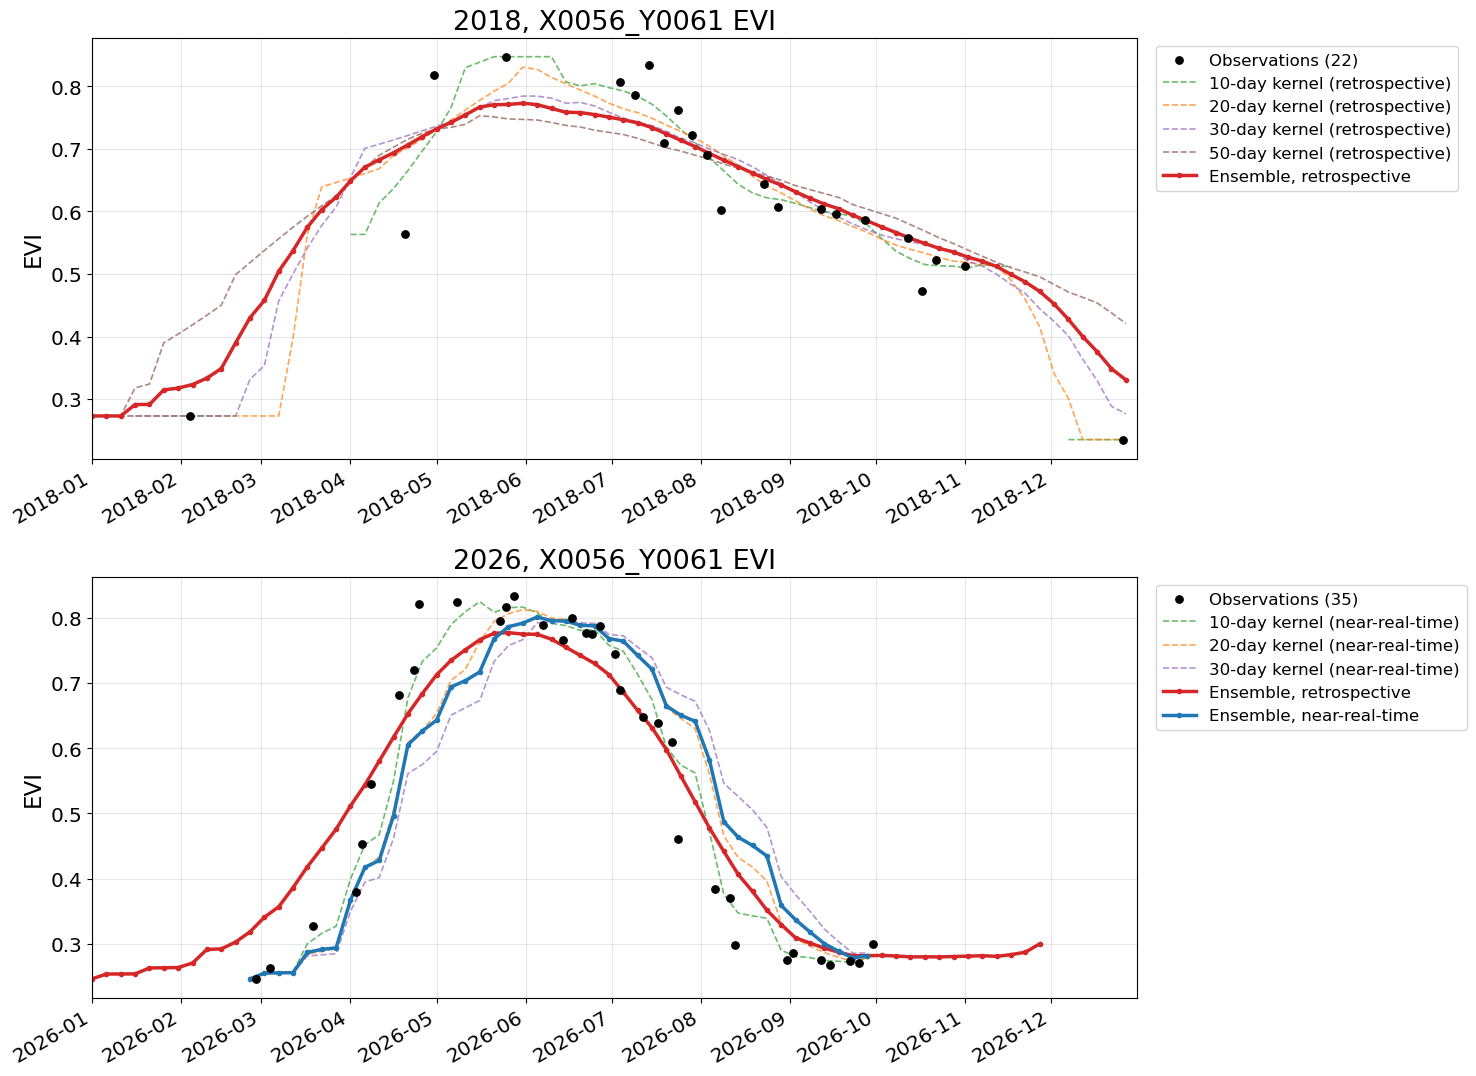

In [4]:
# One pixel's observations and RBF interpolation: 2018 (retrospective) vs this year (retrospective and near-real-time)
from src.disco_ch_operational.visualize_interpolation import plot_pixel
from src.disco_ch_operational.compare import rc_params

force_directory = force_directory if "force_directory" in dir() else r'B:\bloomc\DiscoCH_2026_08_03\FORCE\level3_tss'
force_output = force_output if "force_output" in dir() else os.path.join(output_dir, 'DiscoCH_rbf_10_20_30')
rbf_output = rbf_output if "rbf_output" in dir() else os.path.join(force_output, 'level4_rbf', str(year))
date_to_run_to = date_to_run_to if "date_to_run_to" in dir() else date(year, 10, 5)
force_directory_2018 = r"B:\bloomc\DiscoCH_2026_08_03\FORCE\level_3_2018_tiled"

tile, vi = "X0056_Y0061", "EVI"
row, col = 2425, 2156      # pixel within the tile (None, None = pick one with enough observations)

with plt.rc_context(rc_params(1.2)):
    fig, (ax18, ax26) = plt.subplots(2, 1, figsize=(15, 11))
plot_pixel(
    os.path.join(force_directory_2018, tile, f"2018-2018_001-365_HL_TSA_SEN2L_{vi}_TSS.tif"),
    row=row, col=col, rbf_sigma=(10, 20, 30, 50), rbf_cutoff=0.95, int_day=5,
    lag_days=None,         # retrospective ensemble only
    despike=True, above_noise=3.0, below_noise=1.0,
    title=f"2018, {tile} {vi}", ax=ax18, component_data="retrospective",
)
plot_pixel(
    os.path.join(force_directory, tile, f"{year}0101-{year}1231_001-365_HL_TSA_SEN2L_{vi}_TSS.tif"),
    row=row, col=col, rbf_sigma=(10, 20, 30), rbf_cutoff=0.95, int_day=5,
    lag_days=5, as_of=date_to_run_to,   # as in the Interpolate cell
    component_data="nrt",              # kernel curves near-real-time ("retrospective" = all data)
    despike=False,
    title=f"{year}, {tile} {vi}", ax=ax26,
)
# print_effective_bandwidth=True prints how much smoothing each date really got
fig.savefig(os.path.join(force_output, f"interpolation_{tile}_{vi}_r{row}_c{col}.png"), dpi=200, bbox_inches="tight")
plt.show()
